# Iris Flower Classification
**Oasis Infobyte Data Science Internship — Task 1**

## Objective
Classify Iris flowers into Setosa, Versicolor, or Virginica using their sepal and petal measurements.

## How to run
Open this notebook in Google Colab, then choose **Runtime → Run all**. The Iris dataset is included in scikit-learn; no download is needed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

## 1. Load and inspect the dataset

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values:")
print(df.isnull().sum())
display(df.describe())

Dataset shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


\nData types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object
\nMissing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 2. Exploratory data analysis

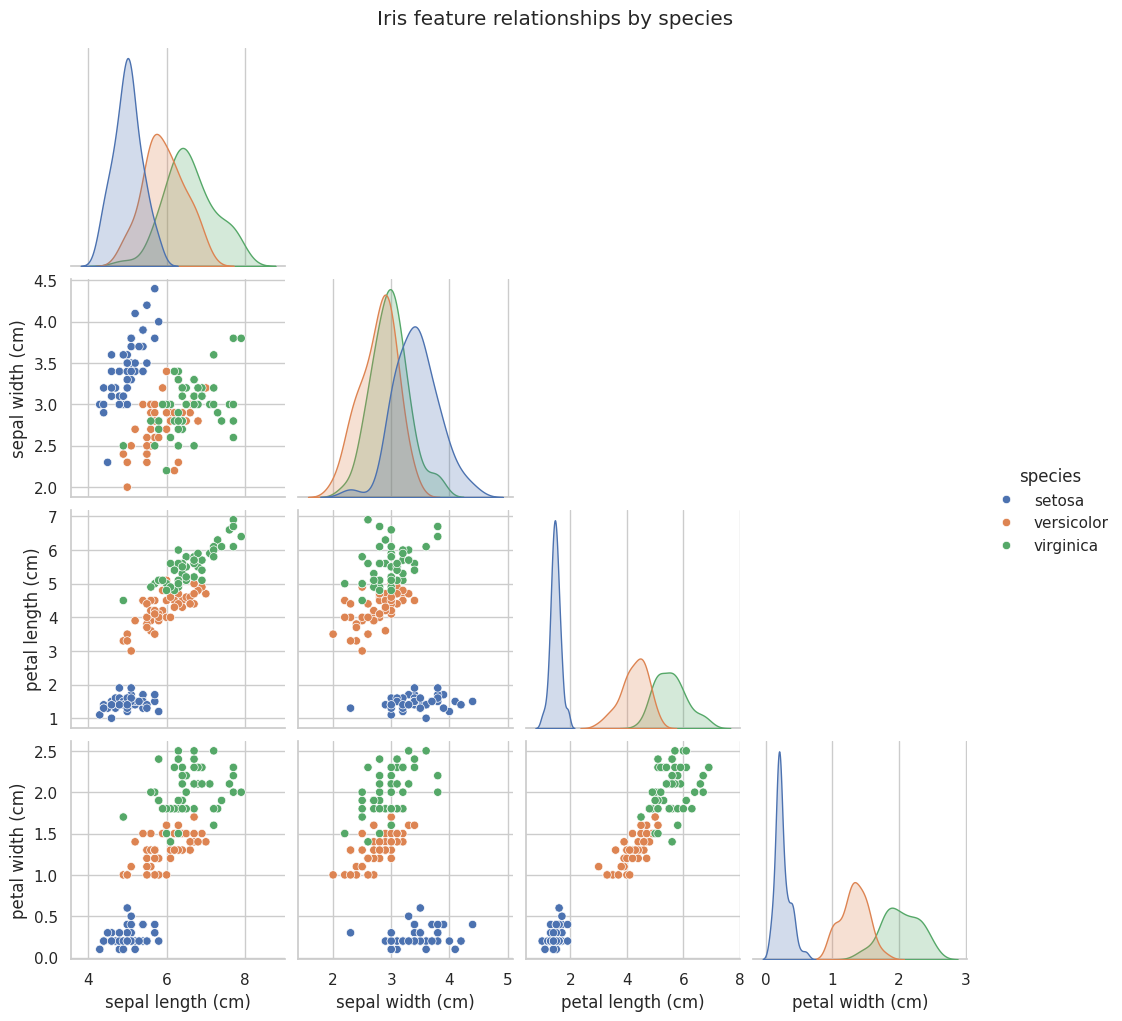

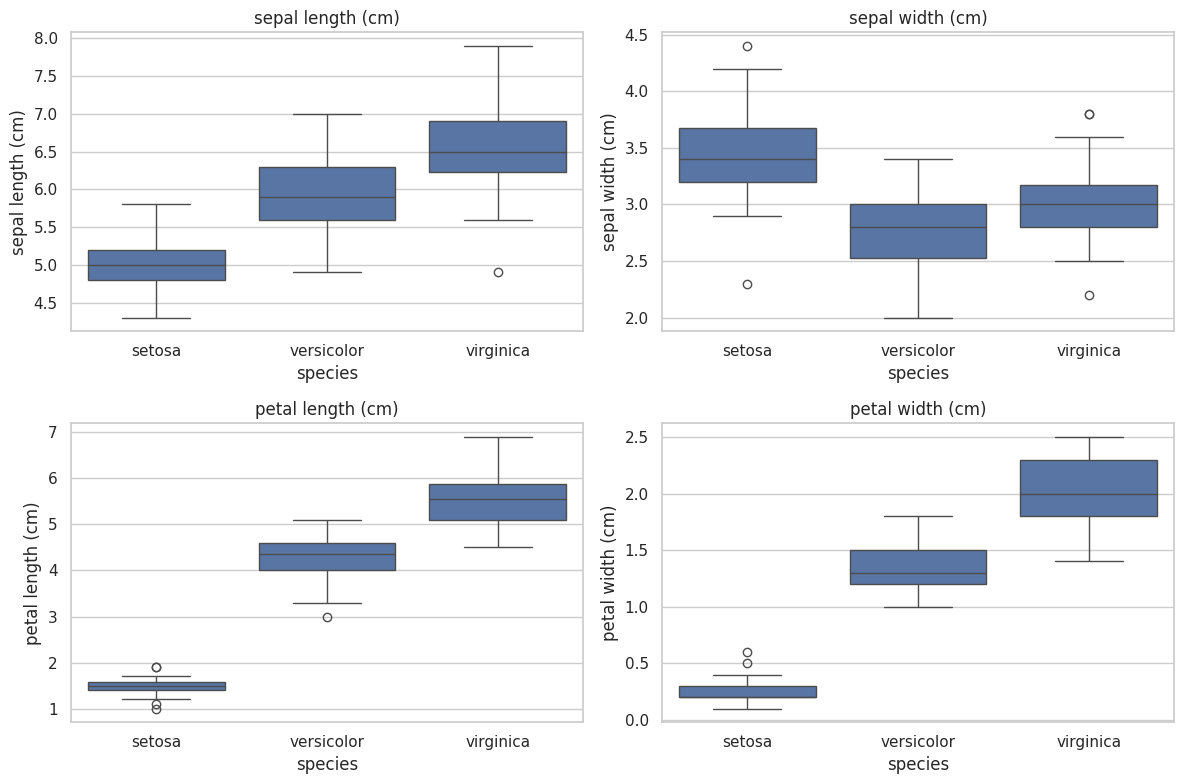

In [3]:
feature_names = iris.feature_names

sns.pairplot(df, vars=feature_names, hue="species", corner=True)
plt.suptitle("Iris feature relationships by species", y=1.02)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, feature_names):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## 3. Feature selection discussion
Petal length and petal width are often the most discriminative features because the species show clearer separation on these measurements than on sepal measurements. The plots below let us inspect that pattern in this dataset.

In [4]:
X = df[feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 120
Test rows: 30


## 4. Train and compare two classifiers

\nLogistic Regression accuracy: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



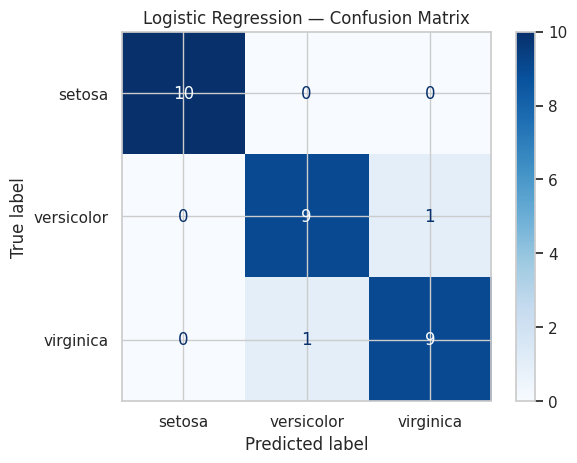

\nK-Nearest Neighbors accuracy: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



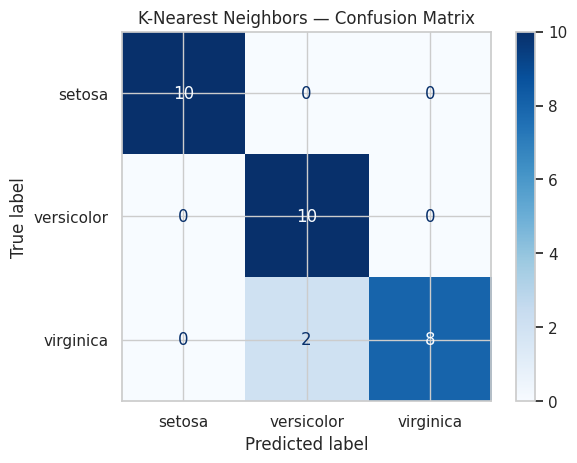

Best model on this test split: Logistic Regression (0.933 accuracy)


In [5]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "K-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    results[name] = {"model": model, "predictions": predictions, "accuracy": accuracy}
    print(f"\\n{name} accuracy: {accuracy:.3f}")
    print(classification_report(y_test, predictions, target_names=iris.target_names, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=iris.target_names, cmap="Blues"
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

best_name = max(results, key=lambda name: results[name]["accuracy"])
print(f"Best model on this test split: {best_name} ({results[best_name]['accuracy']:.3f} accuracy)")

Conclusion

The Iris Flower Classification project successfully used machine learning to classify iris flowers into Setosa, Versicolor, and Virginica based on sepal and petal measurements. Several classification models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The K-Nearest Neighbors model achieved 93.3% accuracy on the test dataset. The results demonstrate that machine learning can classify iris species effectively, although some confusion between Versicolor and Virginica remains. Model performance may vary with different train-test splits and parameter settings.